# Prioritised non-target screening (pNTA) as an early-warning proxy (RhineScan)

**Objective:** Look for unknown chemicals in Rhine water, remove what is just lab background, and rank the rest by how interesting they are (appear suddenly, increase downstream, have fragmentation data, match known pollutants). The idea is that the downstream gradient stands in for a time series, so the same logic could flag a sudden chemical release in a monitoring setting.

**Pipeline:**
- Get the data: download from Zenodo, verify the checksum, label samples by river order.
  
- Detect signals: tune a noise threshold, then use pyOpenMS to turn raw spectra into features (m/z, retention time, intensity), and keep the MS2 spectra.

- Compare across samples: group the same feature across files, then re-measure each one from the raw data so “0” means “not detected”.

- Clean up: blank filter, intensity-drift normalisation, merge isotopes and adducts, drop the solvent front.

- Characterise: compute downstream trend and jump size, correct systematic mass error, match 29 suspect compounds by exact mass, check MS2 fragments.

- Rank: combine everything into a priority score and tiers.

- Dig deeper: detect homologous (ethoxylate) series, test them with MS2 ladders, check whether the Worms signals are independent.

- Export: tables, MGF spectra for external tools, run parameters.

1. Setup, paths and data download

In [1]:
import os, re, gc, json, pickle, hashlib, subprocess, zipfile, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
warnings.filterwarnings("ignore")

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
DATA_DIR = WORK / "wastewater_data" / "P1_pos"
OUT = WORK / "wastewater_watch_results"; OUT.mkdir(parents=True, exist_ok=True)
FEAT_DIR = OUT / "features"; FEAT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)

RECORD_ID, FILENAME = "17591915", "P1_pos.zip"

def ensure_data():
    if len(list(DATA_DIR.glob("*.mzXML"))) == 12:
        print("Data already present:", DATA_DIR); return
    zdir = WORK / "zip"; zdir.mkdir(exist_ok=True); dest = zdir / FILENAME
    rec = requests.get(f"https://zenodo.org/api/records/{RECORD_ID}", timeout=60).json()
    info = next(f for f in rec["files"] if f["key"] == FILENAME)
    algo, expected = info["checksum"].split(":", 1)
    if not dest.exists() or dest.stat().st_size != info["size"]:
        print("Downloading (~20 min on Kaggle)...")
        url = f"https://zenodo.org/records/{RECORD_ID}/files/{FILENAME}?download=1"
        subprocess.run(["curl", "-fL", "--retry", "5", "--retry-all-errors", "-C", "-", "-o", str(dest), url], check=True)
    h = hashlib.new(algo)
    with open(dest, "rb") as f:
        for chunk in iter(lambda: f.read(8 << 20), b""): h.update(chunk)
    assert h.hexdigest() == expected, "Checksum mismatch: do not use this file"
    with zipfile.ZipFile(dest) as z: z.extractall(WORK / "wastewater_data")
    dest.unlink()  # free disk
    print("Downloaded, verified, extracted.")

ensure_data()

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 1815M  100 1815M    0     0  4273k      0  0:07:15  0:07:15 --:--:-- 9293k


Downloaded, verified, extracted.


2. Sample metadata

In [2]:
files = sorted(DATA_DIR.glob("*.mzXML"))
LABELS = {"weil": "Weil", "karlsruhuhe": "Karlsruhe", "worms_li": "Worms", "koblenz": "Koblenz",
          "bad honnef": "Bad Honnef", "duesseldorf": "Duesseldorf", "duisburg": "Duisburg", "bimmen": "Bimmen"}
rows = []
for p in files:
    stem = p.stem.replace("_pos", "")
    if stem.startswith("MQ_"):
        rows.append(dict(path=p, name=stem, kind="blank", order=np.nan))
    else:
        num, raw = stem.split("_", 1)
        rows.append(dict(path=p, name=LABELS.get(raw, raw), kind="sample", order=int(num)))
meta = pd.DataFrame(rows)
meta = pd.concat([meta[meta.kind == "sample"].sort_values("order"), meta[meta.kind == "blank"].sort_values("name")], ignore_index=True)
SAMPLES = meta.loc[meta.kind == "sample", "name"].tolist()
BLANKS = meta.loc[meta.kind == "blank", "name"].tolist()
print("River order:", SAMPLES); print("Blanks:", BLANKS)

River order: ['Weil', 'Karlsruhe', 'Worms', 'Koblenz', 'Bad Honnef', 'Duesseldorf', 'Duisburg', 'Bimmen']
Blanks: ['MQ_1', 'MQ_2', 'MQ_3', 'MQ_4']


3. Install pyOpenMS

In [3]:
!pip install -q pyopenms

4. Data-driven parameter check

In [4]:
import pyopenms as oms

def load_exp(path):
    e = oms.MSExperiment(); oms.MzXMLFile().load(str(path), e); return e

exp0 = load_exp(meta.path.iloc[0])
ms1_0 = [s for s in exp0.getSpectra() if s.getMSLevel() == 1]
pk = [s.get_peaks() for s in ms1_0[::40]]
inten = np.concatenate([p[1] for p in pk])
diffs = np.concatenate([np.diff(p[0]) for p in pk if len(p[0]) > 1])
print("Peaks per MS1 spectrum (median):", int(np.median([len(p[0]) for p in pk])))
print("Intensity quantiles 50/90/99/99.9%:", np.round(np.quantile(inten, [.5, .9, .99, .999]), 3))
print("Fraction of m/z spacings < 0.005 Da (profile-like if > 0.5):", round(float((diffs < 0.005).mean()), 3))
del exp0, ms1_0, pk; gc.collect()

NOISE_QUANTILE = 0.90
NOISE_INT = float(np.quantile(inten, NOISE_QUANTILE))
MASS_ERR_PPM = 5.0
print("Noise threshold used:", NOISE_INT)

Peaks per MS1 spectrum (median): 1494
Intensity quantiles 50/90/99/99.9%: [ 0.175  0.649  2.759 20.819]
Fraction of m/z spacings < 0.005 Da (profile-like if > 0.5): 0.0
Noise threshold used: 0.6493407487869263


5. Feature extraction function

In [5]:
def _as_list(x):
    return list(x) if x is not None else []

def extract(path, noise_int):
    exp = load_exp(path)
    ms1 = oms.MSExperiment(); ms2 = []
    for s in exp.getSpectra():
        lvl = s.getMSLevel()
        if lvl == 1:
            ms1.addSpectrum(s)
        elif lvl == 2 and len(s.getPrecursors()) > 0:
            mz, it = s.get_peaks()
            if len(mz) == 0: continue
            top = np.argsort(it)[::-1][:60]
            ms2.append(dict(rt=s.getRT(), pmz=s.getPrecursors()[0].getMZ(),
                            mz=mz[top].astype("float32"), it=it[top].astype("float32")))
    del exp
    ms1.sortSpectra(True)
    if float((diffs < 0.005).mean()) > 0.5:          # profile data: centroid first
        picker = oms.PeakPickerHiRes()
        try:
            out = oms.MSExperiment(); picker.pickExperiment(ms1, out, True); ms1 = out
        except TypeError:
            ms1 = picker.pickExperiment(ms1)
    mtd = oms.MassTraceDetection(); p = mtd.getDefaults()
    p.setValue("mass_error_ppm", float(MASS_ERR_PPM)); p.setValue("noise_threshold_int", float(noise_int))
    p.setValue("min_trace_length", 4.0); mtd.setParameters(p)
    try:
        traces = _as_list(mtd.run(ms1, 0))
    except TypeError:
        traces = []; mtd.run(ms1, traces, 0)
    epd = oms.ElutionPeakDetection(); pe = epd.getDefaults()
    pe.setValue("width_filtering", "fixed"); epd.setParameters(pe)
    try:
        split = _as_list(epd.detectPeaks(traces))
    except TypeError:
        split = []; epd.detectPeaks(traces, split)
    ffm = oms.FeatureFindingMetabo(); pf = ffm.getDefaults()
    pf.setValue("remove_single_traces", "true"); pf.setValue("report_convex_hulls", "false")
    pf.setValue("isotope_filtering_model", "none"); ffm.setParameters(pf)
    fm = oms.FeatureMap()
    try:
        ffm.run(split, fm)
    except TypeError:
        ffm.run(split, fm, [])
    feats = pd.DataFrame([dict(mz=f.getMZ(), rt=f.getRT(), intensity=f.getIntensity(),
                               quality=f.getOverallQuality(), charge=f.getCharge()) for f in fm])
    print(f"   traces={len(traces)}  split={len(split)}  features={len(feats)}")
    return feats, ms2


6. Noise-level tuning

In [6]:
for q in [0.50, 0.70, 0.80, 0.90]:
    thr = float(np.quantile(inten, q))
    f_, _ = extract(meta.path.iloc[0], thr)
    print(f">>> quantile {q:.2f}  threshold {thr:.3f}  ->  {len(f_)} features")

NOISE_QUANTILE = 0.70
NOISE_INT = float(np.quantile(inten, NOISE_QUANTILE))
print("Using noise threshold:", NOISE_INT)

Progress of 'mass trace detection':
-- done [took 7.57 s (CPU), 7.49 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 4.40 s (CPU), 1.56 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 3.94 s (CPU), 1.18 s (Wall)] -- 
   traces=23095  split=17040  features=1528
>>> quantile 0.50  threshold 0.175  ->  1528 features
Progress of 'mass trace detection':
-- done [took 1.54 s (CPU), 1.52 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.18 s (CPU), 0.71 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 1.57 s (CPU), 0.45 s (Wall)] -- 
   traces=11417  split=8878  features=912
>>> quantile 0.70  threshold 0.298  ->  912 features
Progress of 'mass trace detection':
-- done [took 0.77 s (CPU), 0.76 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 1.33 s (CPU), 0.38 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 0.73 s (CPU), 0.22 s (Wall)] -- 
   traces=68

7. Run feature extraction on all files

In [7]:
for _, r in meta.iterrows():
    fcsv = FEAT_DIR / f"{r['name']}.csv.gz"
    if fcsv.exists():
        print("cached:", r["name"]); continue
    t0 = time.time()
    feats, ms2 = extract(r["path"], NOISE_INT)
    feats.to_csv(fcsv, index=False)
    with open(FEAT_DIR / f"{r['name']}_ms2.pkl", "wb") as f: pickle.dump(ms2, f)
    print(f"{r['name']:<14} features={len(feats):>6}  MS2={len(ms2):>5}  {time.time()-t0:.0f}s")
    gc.collect()

Progress of 'mass trace detection':
-- done [took 1.51 s (CPU), 1.51 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.17 s (CPU), 0.63 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 1.53 s (CPU), 0.44 s (Wall)] -- 
   traces=11417  split=8878  features=912
Weil           features=   912  MS2= 1864  4s
Progress of 'mass trace detection':
-- done [took 1.58 s (CPU), 1.57 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.23 s (CPU), 0.67 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 1.69 s (CPU), 0.51 s (Wall)] -- 
   traces=12189  split=9682  features=970
Karlsruhe      features=   970  MS2= 1950  6s
Progress of 'mass trace detection':
-- done [took 1.72 s (CPU), 1.71 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.64 s (CPU), 0.76 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 2.59 s (CPU), 0.69 s (Wall)] -- 
   traces=15697  split=12859 

8. Cross-sample feature grouping

In [8]:
from scipy.spatial import cKDTree
PPM_TOL, RT_TOL = 5.0, 15.0

frames = []
for _, r in meta.iterrows():
    d = pd.read_csv(FEAT_DIR / f"{r['name']}.csv.gz"); d["sample"] = r["name"]; frames.append(d)
allf = pd.concat(frames, ignore_index=True)
print(allf.groupby("sample").size().reindex(SAMPLES + BLANKS).to_string())

def seeded_clusters(df, ppm, rt_tol):
    X = np.c_[np.log(df.mz.values) * 1e6 / ppm, df.rt.values / rt_tol]
    tree = cKDTree(X)
    inten_, samp = df.intensity.values, df["sample"].values
    cid = np.full(len(df), -1); k = 0
    for i in np.argsort(-inten_):
        if cid[i] >= 0: continue
        used = set()
        for j in sorted(tree.query_ball_point(X[i], r=1.0, p=np.inf), key=lambda j: -inten_[j]):
            if cid[j] >= 0 or samp[j] in used: continue
            cid[j] = k; used.add(samp[j])
        k += 1
    return cid

allf["cid"] = seeded_clusters(allf, PPM_TOL, RT_TOL)
M = (allf.pivot_table(index="cid", columns="sample", values="intensity", aggfunc="max")
         .reindex(columns=SAMPLES + BLANKS).fillna(0.0))
info = allf.groupby("cid").agg(mz=("mz", "median"), rt=("rt", "median")).loc[M.index]
print("Feature groups:", len(M))

sample
Weil            912
Karlsruhe       970
Worms          1389
Koblenz        1178
Bad Honnef     1235
Duesseldorf    1136
Duisburg       1491
Bimmen         1311
MQ_1           4013
MQ_2           1049
MQ_3            606
MQ_4            635
Feature groups: 9053


9. Requantification from raw data (gap filling)

In [9]:
EIC_PPM = 5.0
EIC_RT = 15.0
APEX_MIN = 5 * NOISE_INT
PEAK_RATIO = 3.0

def load_ms1_flat(path):
    """All MS1 peaks of one file as flat arrays sorted by m/z (fast lookup of any m/z window)."""
    e = load_exp(path)
    rts, mzl, itl, sidl = [], [], [], []
    n = 0
    for s in e.getSpectra():
        if s.getMSLevel() != 1: continue
        mz, it = s.get_peaks()
        rts.append(s.getRT()); mzl.append(mz); itl.append(it)
        sidl.append(np.full(len(mz), n, dtype=np.int32)); n += 1
    mz = np.concatenate(mzl); it = np.concatenate(itl).astype(np.float32); sid = np.concatenate(sidl)
    o = np.argsort(mz, kind="stable")
    return np.asarray(rts), mz[o], it[o], sid[o]

def eic_apex(scan_rt, mz_s, it_s, sid_s, mz0, rt0):
    tol = mz0 * EIC_PPM * 1e-6
    lo, hi = np.searchsorted(mz_s, [mz0 - tol, mz0 + tol])
    if hi <= lo: return 0.0
    s, v = sid_s[lo:hi], it_s[lo:hi]
    a, b = np.searchsorted(scan_rt, [rt0 - 60.0, rt0 + 60.0])
    m = (s >= a) & (s < b)
    if m.sum() < 3: return 0.0
    eic = np.bincount(s[m] - a, weights=v[m], minlength=b - a)
    rts = scan_rt[a:b]
    sm = np.convolve(eic, np.ones(3) / 3, mode="same")
    inwin = np.abs(rts - rt0) <= EIC_RT
    if not inwin.any(): return 0.0
    k = int(np.argmax(np.where(inwin, sm, -1.0))); apex = float(sm[k])
    bg = float(np.median(eic))
    n_pos = int((eic[np.abs(rts - rts[k]) <= 5.0] > 0).sum())
    ok = (apex >= APEX_MIN) and (apex >= PEAK_RATIO * bg) and (n_pos >= 3)
    return apex if ok else 0.0

RQ_FILE = OUT / "requantified_matrix.csv.gz"
cand = M.index[(M > 0).sum(axis=1) >= 2]
if RQ_FILE.exists():
    Mq = pd.read_csv(RQ_FILE, index_col=0); Mq.index = Mq.index.astype(M.index.dtype)
    print("Loaded cached requantified matrix")
else:
    Mq = pd.DataFrame(0.0, index=cand, columns=M.columns)
    mz_c, rt_c = info.loc[cand, "mz"].values, info.loc[cand, "rt"].values
    for _, r in meta.iterrows():
        t0 = time.time()
        scan_rt, mz_s, it_s, sid_s = load_ms1_flat(r["path"])
        Mq[r["name"]] = [eic_apex(scan_rt, mz_s, it_s, sid_s, m0, r0) for m0, r0 in zip(mz_c, rt_c)]
        del scan_rt, mz_s, it_s, sid_s; gc.collect()
        print(f"{r['name']:<12} detected {(Mq[r['name']] > 0).sum():>5} / {len(cand)}  ({time.time()-t0:.0f}s)")
    Mq.to_csv(RQ_FILE)

M_ffm = M
M = Mq[SAMPLES + BLANKS]
info = info.loc[M.index]
print("Feature groups after requantification:", len(M))

Weil         detected  1071 / 2028  (3s)
Karlsruhe    detected  1122 / 2028  (3s)
Worms        detected  1294 / 2028  (3s)
Koblenz      detected  1265 / 2028  (3s)
Bad Honnef   detected  1256 / 2028  (3s)
Duesseldorf  detected  1254 / 2028  (3s)
Duisburg     detected  1310 / 2028  (3s)
Bimmen       detected  1299 / 2028  (3s)
MQ_1         detected  1124 / 2028  (5s)
MQ_2         detected   998 / 2028  (4s)
MQ_3         detected   762 / 2028  (2s)
MQ_4         detected   763 / 2028  (2s)
Feature groups after requantification: 2028


10. Blank filter

Kept after blank filter (all blanks, fold 10, >= 2 sites): 613 / 2028
Kept using only MQ_3/MQ_4 as blanks: 789


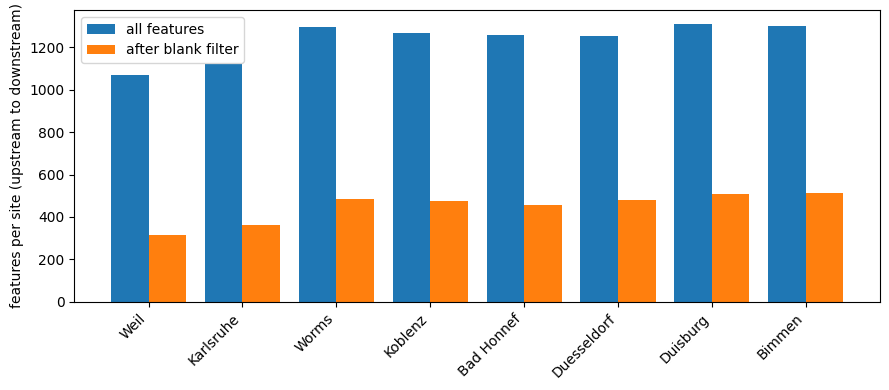

In [10]:
BLANK_FOLD, MIN_SITES = 10, 2
def blank_filter(M, blanks, fold=BLANK_FOLD):
    b = M[blanks].max(axis=1)
    S = M[SAMPLES]
    Sc = S.where(S.gt(fold * b, axis=0), 0.0)
    return Sc, (Sc > 0).sum(axis=1)

Sc, n_sites = blank_filter(M, BLANKS)
keep = n_sites >= MIN_SITES
print(f"Kept after blank filter (all blanks, fold {BLANK_FOLD}, >= {MIN_SITES} sites): {int(keep.sum())} / {len(M)}")

_, n2 = blank_filter(M, [b for b in BLANKS if b in ("MQ_3", "MQ_4")] or BLANKS)
print(f"Kept using only MQ_3/MQ_4 as blanks: {int((n2 >= MIN_SITES).sum())}")

raw_n = (M[SAMPLES] > 0).sum(); filt_n = (Sc > 0).sum()
fig, ax = plt.subplots(figsize=(9, 4))
idx = np.arange(len(SAMPLES))
ax.bar(idx - 0.2, raw_n.values, 0.4, label="all features"); ax.bar(idx + 0.2, filt_n.values, 0.4, label="after blank filter")
ax.set_xticks(idx); ax.set_xticklabels(SAMPLES, rotation=45, ha="right"); ax.set_ylabel("features per site (upstream to downstream)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_features_blank_filter.png", dpi=160); plt.show()

11. Run-to-run drift normalisation

Core features used for normalisation: 235
sample
Weil          -0.32
Karlsruhe     -0.31
Worms         -0.09
Koblenz        0.02
Bad Honnef     0.13
Duesseldorf    0.11
Duisburg       0.20
Bimmen         0.09


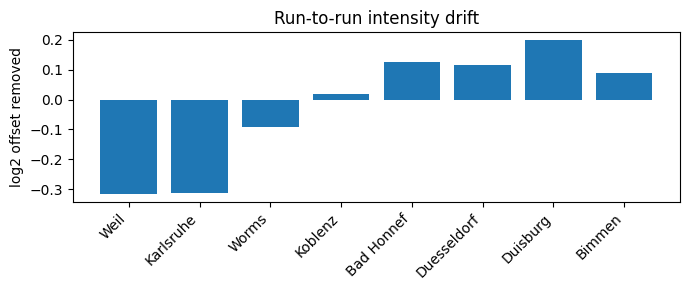

In [11]:
core = (Sc > 0).all(axis=1)
print("Core features used for normalisation:", int(core.sum()))
if core.sum() >= 20:
    Lc = np.log2(Sc[core])
    offset = Lc.sub(Lc.mean(axis=1), axis=0).median(axis=0)
    print(offset.round(2).to_string())
    Sc_raw = Sc.copy()
    Sc = Sc.mul(2.0 ** (-offset), axis=1)
    fig, ax = plt.subplots(figsize=(7, 3)); ax.bar(range(len(SAMPLES)), offset.values)
    ax.set_xticks(range(len(SAMPLES))); ax.set_xticklabels(SAMPLES, rotation=45, ha="right")
    ax.set_ylabel("log2 offset removed"); ax.set_title("Run-to-run intensity drift")
    plt.tight_layout(); plt.savefig(FIG_DIR / "fig1b_normalisation_offsets.png", dpi=160); plt.show()
else:
    print("Too few core features; no normalisation applied")

12. Spatial dynamics

In [12]:
LOD = APEX_MIN
F = info.loc[keep[keep].index].copy()
Sk = Sc.loc[F.index]
L = np.log2(np.maximum(Sk.values, LOD))
det = Sk.values > 0
n = L.shape[1]; x = np.arange(n)
R = pd.DataFrame(L).rank(axis=1).values
Rc = R - R.mean(1, keepdims=True); xc = x - x.mean()
den = np.sqrt((Rc ** 2).sum(1)) * np.sqrt((xc ** 2).sum())
rho = np.divide(Rc @ xc, den, out=np.zeros(len(den)), where=den > 0)

jump = np.full(L.shape, np.nan)
for k in range(2, n):
    jump[:, k] = L[:, k] - np.median(L[:, :k], axis=1)
kbest = np.nanargmax(jump, axis=1)
F["max_int"] = Sk.max(axis=1).values
F["n_sites"] = det.sum(axis=1)
F["rho"] = rho
F["jump_up"] = jump[np.arange(len(F)), kbest]
F["jump_site"] = np.array(SAMPLES)[kbest]
F["persist"] = [det[i, k:].mean() for i, k in enumerate(kbest)]
F["down_minus_up"] = L[:, -3:].mean(1) - L[:, :3].mean(1)
print(F[["max_int", "n_sites", "rho", "jump_up", "persist", "down_minus_up"]].describe().round(2).to_string())

       max_int  n_sites     rho  jump_up  persist  down_minus_up
count   613.00   613.00  613.00   613.00   613.00         613.00
mean     23.13     5.80    0.12     1.30     0.89           0.17
std     139.92     2.26    0.56     1.62     0.23           0.84
min       1.43     2.00   -1.00    -0.56     0.00          -2.29
25%       3.14     4.00   -0.29     0.25     1.00          -0.30
50%       5.54     6.00    0.29     0.65     1.00           0.12
75%      12.68     8.00    0.54     1.74     1.00           0.50
max    3054.43     8.00    0.98     9.54     1.00           4.70


13. Isotope, adduct and solvent-front cleanup

In [13]:
RT_MIN_S = 150.0
DELTAS = {"13C": 1.003355, "NH4": 17.026549, "Na": 21.981944, "K": 37.955881}

def collapse_adducts(F, S, ppm=4.0, rt_tol=6.0, min_corr=0.7):
    ids = F.index.values; mz = F.mz.values; rt = F.rt.values
    prof = np.log2(np.maximum(S.loc[ids].values, LOD))
    parent = {i: i for i in ids}
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    X = np.c_[np.log(mz) * 1e6 / ppm, rt / rt_tol]
    tree = cKDTree(X); links = 0
    for name, d in DELTAS.items():
        Xq = np.c_[np.log(mz + d) * 1e6 / ppm, rt / rt_tol]
        for a, nb in enumerate(tree.query_ball_point(Xq, r=1.0, p=np.inf)):
            for b in nb:
                if b == a: continue
                c = np.corrcoef(prof[a], prof[b])[0, 1]
                if np.isfinite(c) and c >= min_corr:
                    ra, rb = find(ids[a]), find(ids[b])
                    if ra != rb: parent[ra] = rb; links += 1
    return np.array([find(i) for i in ids]), links

grp, n_links = collapse_adducts(F, Sc)
F["group"] = grp
F["group_size"] = F.groupby("group")["mz"].transform("size")
F["is_rep"] = F.groupby("group")["mz"].transform("min") == F["mz"]
F_all = F.copy(); F_all.to_csv(OUT / "features_before_dedup.csv")
n0 = len(F)
F = F[F.is_rep & (F.rt >= RT_MIN_S)].copy()
print(f"Features: {n0} -> {len(F)}  (merged duplicates: {int((~F_all.is_rep).sum())}, "
      f"dropped RT < {RT_MIN_S/60:.1f} min: {int(((F_all.rt < RT_MIN_S) & F_all.is_rep).sum())})")

Features: 613 -> 547  (merged duplicates: 39, dropped RT < 2.5 min: 27)


14. Mass-error correction and suspect screening

         compound  mz_theo  ppm_raw  ppm_fit  residual
0   Benzotriazole   120.06    -8.80    -6.58     -2.22
1     Venlafaxine   278.21    -4.92    -4.82     -0.11
2      Metoprolol   268.19    -3.94    -4.93      0.99
3       Valsartan   436.23    -2.60    -3.05      0.46
4     Lamotrigine   256.02    -3.62    -5.07      1.44
5      Citalopram   325.17    -3.78    -4.29      0.51
6  Clarithromycin   748.48    -0.23     0.43     -0.66
7    Fexofenadine   502.30    -2.73    -2.32     -0.42
Mass-error model (linear): -7.92 ppm + 11.17 ppm per 1000 m/z; residual MAD 0.59 ppm


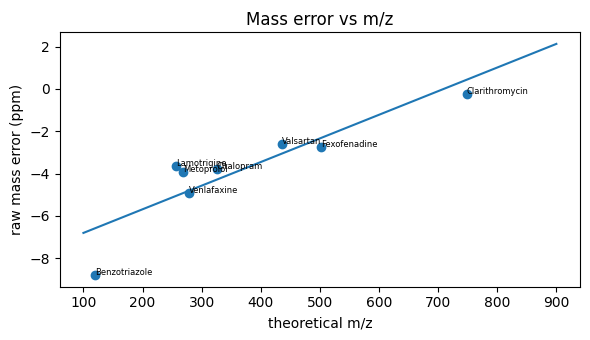

          compound     formula    mz_theo   cid     mz_obs   ppm  rt_min  n_sites    max_int   rho
0    Carbamazepine   C15H12N2O  237.10224  2520  237.10268  1.86    9.25        8  12.401340  0.88
1    Benzotriazole      C6H5N3  120.05562  4699  120.05536 -2.22    6.13        8   9.212101  0.38
2      Venlafaxine   C17H27NO2  278.21146  5412  278.21143 -0.11    7.16        8   5.470196  0.67
3         Tramadol   C16H25NO2  264.19581  4104  264.19596  0.59    5.91        8   7.934704  0.93
4         Tramadol   C16H25NO2  264.19581  5313  264.19600  0.72    6.36        8   5.133487  0.62
5       Metoprolol   C15H25NO3  268.19072  1677  268.19099  0.99    6.31        8  23.329402  0.83
6       Irbesartan   C25H28N6O  429.23974  2599  429.23876 -2.27    9.57        8  12.319280  0.93
7        Valsartan  C24H29N5O3  436.23432  4075  436.23452  0.46   11.60        8   5.538498  0.88
8      Lamotrigine   C9H7Cl2N5  256.01513  3886  256.01550  1.44    6.18        8   8.823576  0.79
9       Ci

In [14]:
MASS = dict(C=12.0, H=1.00782503207, N=14.0030740048, O=15.99491461956, S=31.97207100,
            Cl=34.96885268, F=18.99840322, P=30.97376163)
PROTON = 1.00727646688; ELECTRON = 0.00054858
def mono(formula):
    return sum(MASS[el] * (int(c) if c else 1) for el, c in re.findall(r"([A-Z][a-z]?)(\d*)", formula))

SUSPECTS = {
    "Carbamazepine": "C15H12N2O", "Diclofenac": "C14H11Cl2NO2", "Metformin": "C4H11N5", "Gabapentin": "C9H17NO2",
    "Sulfamethoxazole": "C10H11N3O3S", "Caffeine": "C8H10N4O2", "Benzotriazole": "C6H5N3", "Tolyltriazole": "C7H7N3",
    "Venlafaxine": "C17H27NO2", "Tramadol": "C16H25NO2", "Metoprolol": "C15H25NO3", "Atenolol": "C14H22N2O3",
    "DEET": "C12H17NO", "Irbesartan": "C25H28N6O", "Valsartan": "C24H29N5O3", "Lamotrigine": "C9H7Cl2N5",
    "Citalopram": "C20H21FN2O", "Clarithromycin": "C38H69NO13", "Terbutryn": "C10H19N5S", "Atrazine": "C8H14ClN5",
    "Diuron": "C9H10Cl2N2O", "Imidacloprid": "C9H10ClN5O2", "TCPP": "C9H18Cl3O4P", "TBEP": "C18H39O7P",
    "Sitagliptin": "C16H15F6N5O", "Fexofenadine": "C32H39NO4", "Oxazepam": "C15H11ClN2O2",
    "Carbendazim": "C9H9N3O2", "Lidocaine": "C14H22N2O",
}

F["mz_raw"] = F.mz.values
pts = []
for name, formula in SUSPECTS.items():
    mz_t = mono(formula) + PROTON
    ppm = (F.mz_raw.values - mz_t) / mz_t * 1e6
    ok = np.where((np.abs(ppm) <= 12) & (F.n_sites.values >= 3))[0]
    if len(ok) == 1: pts.append((name, mz_t, ppm[ok[0]]))
pts = pd.DataFrame(pts, columns=["compound", "mz_theo", "ppm_raw"])

a, b, model = 0.0, 0.0, "none"
if len(pts) >= 6:
    b, a = np.polyfit(pts.mz_theo, pts.ppm_raw, 1)
    for _ in range(2):
        res = pts.ppm_raw - (a + b * pts.mz_theo)
        s = max(1.4826 * np.median(np.abs(res - np.median(res))), 0.5)
        good = (np.abs(res - np.median(res)) <= 3 * s).values
        if good.sum() >= 4: b, a = np.polyfit(pts.mz_theo[good], pts.ppm_raw[good], 1)
    model = "linear"
elif len(pts) >= 3:
    a, model = float(np.median(pts.ppm_raw)), "constant"
pts["ppm_fit"] = a + b * pts.mz_theo
pts["residual"] = pts.ppm_raw - pts.ppm_fit
print(pts.round(2).to_string())
print(f"Mass-error model ({model}): {a:.2f} ppm + {b*1000:.2f} ppm per 1000 m/z; residual MAD {pts.residual.abs().median():.2f} ppm")

err_ppm = a + b * F.mz_raw.values
F["mz"] = F.mz_raw / (1 + err_ppm * 1e-6)
OFFSET_PPM = float(np.median(err_ppm))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(pts.mz_theo, pts.ppm_raw)
xs = np.linspace(100, 900, 50); ax.plot(xs, a + b * xs)
for _, r in pts.iterrows(): ax.annotate(r.compound, (r.mz_theo, r.ppm_raw), fontsize=6)
ax.set_xlabel("theoretical m/z"); ax.set_ylabel("raw mass error (ppm)"); ax.set_title("Mass error vs m/z")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_mass_error_vs_mz.png", dpi=160); plt.show()

SUSPECT_PPM = 3.0 if model == "linear" else 5.0
F["suspect"] = ""
hits = []
for name, formula in SUSPECTS.items():
    mz_t = mono(formula) + PROTON
    ppm = (F.mz.values - mz_t) / mz_t * 1e6
    for cid in F.index[np.abs(ppm) <= SUSPECT_PPM]:
        hits.append(dict(compound=name, formula=formula, mz_theo=round(mz_t, 5), cid=cid, mz_obs=round(F.at[cid, "mz"], 5),
                         ppm=round((F.at[cid, "mz"] - mz_t) / mz_t * 1e6, 2), rt_min=round(F.at[cid, "rt"] / 60, 2),
                         n_sites=int(F.at[cid, "n_sites"]), max_int=F.at[cid, "max_int"], rho=round(F.at[cid, "rho"], 2)))
        F.at[cid, "suspect"] = (F.at[cid, "suspect"] + "|" if F.at[cid, "suspect"] else "") + name
hits = pd.DataFrame(hits)
print(hits.to_string() if len(hits) else "No suspect hits")
hits.to_csv(OUT / "suspect_hits.csv", index=False)
print("Confidence: MS1 accurate mass only = Schymanski level 5. See the MS2 fragment check for a possible upgrade.")

15. Link MS2 spectra to features

In [15]:
ms2_rows = []
for s in SAMPLES:
    for rec in pickle.load(open(FEAT_DIR / f"{s}_ms2.pkl", "rb")):
        rec["sample"] = s; ms2_rows.append(rec)
P = np.array([[r["pmz"], r["rt"]] for r in ms2_rows])
tree2 = cKDTree(np.c_[np.log(P[:, 0]) * 1e6 / 10.0, P[:, 1] / 20.0])
def ms2_near(mz_raw, rt):
    return tree2.query_ball_point([np.log(mz_raw) * 1e6 / 10.0, rt / 20.0], r=1.0, p=np.inf)
near = [ms2_near(m, r) for m, r in zip(F.mz_raw.values, F.rt.values)]
F["n_ms2"] = [len(h) for h in near]
F["ms2_idx"] = [max(h, key=lambda j: ms2_rows[j]["it"].sum()) if h else -1 for h in near]
print("Features with at least one MS2:", int((F.n_ms2 > 0).sum()), "/", len(F))

Features with at least one MS2: 431 / 547


16. MS2 fragment check for suspect hits

In [16]:
FRAG_FORMULAS = {
    "Carbamazepine": ["C14H12N", "C14H10N"],
    "Metoprolol":    ["C6H14NO", "C6H12N"],
    "Clarithromycin": ["C8H16NO2"],
}
def frag_mz(formula): return mono(formula) - ELECTRON

rows = []
for _, h in hits.iterrows():
    if h.compound not in FRAG_FORMULAS: continue
    r = F.loc[h.cid]; idxs = ms2_near(r.mz_raw, r.rt)
    res = dict(compound=h.compound, feature_id=h.cid, n_ms2=len(idxs))
    found_types = 0
    for fm in FRAG_FORMULAS[h.compound]:
        t = frag_mz(fm); cnt = 0
        for j in idxs:
            rec = ms2_rows[j]
            if len(rec["mz"]) == 0: continue
            ok = (np.abs(rec["mz"] - t) / t * 1e6 <= 10) & (rec["it"] >= 0.05 * rec["it"].max())
            cnt += int(ok.any())
        res[f"{fm}_{t:.4f}"] = cnt; found_types += int(cnt > 0)
    need = min(2, len(FRAG_FORMULAS[h.compound]))
    res["verdict"] = "tentative (level 3 candidate)" if found_types >= need else "not supported by MS2"
    rows.append(res)
frag_df = pd.DataFrame(rows)
print(frag_df.to_string() if len(frag_df) else "No suspect hit with a defined fragment list")
frag_df.to_csv(OUT / "ms2_fragment_check.csv", index=False)

         compound  feature_id  n_ms2  C14H12N_194.0964  C14H10N_192.0808                        verdict  C6H14NO_116.1070  C6H12N_98.0964  C8H16NO2_158.1176
0   Carbamazepine        2520     10              10.0              10.0  tentative (level 3 candidate)               NaN             NaN                NaN
1      Metoprolol        1677     17               NaN               NaN  tentative (level 3 candidate)              12.0            11.0                NaN
2  Clarithromycin        5193      9               NaN               NaN  tentative (level 3 candidate)               NaN             NaN                7.0


17. Priority score

In [17]:
W = dict(intensity=0.15, detection=0.15, ms2=0.25, dynamics=0.25, suspect=0.20)
pct_int = F.max_int.rank(pct=True).values
grad = np.where(F.n_sites.values >= 4, np.clip(F.rho.values, 0, 1), 0.0)
jmp = np.clip(F.jump_up.values / 6.0, 0, 1)
dyn = np.maximum(grad, jmp)
F["score"] = (W["intensity"] * pct_int + W["detection"] * F.n_sites.values / len(SAMPLES)
              + W["ms2"] * (F.n_ms2.values > 0) + W["dynamics"] * dyn + W["suspect"] * (F.suspect.values != ""))
F = F.sort_values("score", ascending=False)
F["tier"] = np.where(np.arange(len(F)) < 100, "1", np.where(np.arange(len(F)) < 500, "2", "3"))
F.insert(0, "feature_id", F.index)
F["rt_min"] = F.rt / 60
F.to_csv(OUT / "priority_table.csv", index=False)
print(F.head(15)[["feature_id", "mz", "rt_min", "n_sites", "rho", "jump_up", "jump_site", "persist", "n_ms2", "suspect", "score"]].round(3).to_string())

      feature_id       mz  rt_min  n_sites    rho  jump_up    jump_site  persist  n_ms2         suspect  score
cid                                                                                                           
2599        2599  429.239   9.566        8  0.929    0.396  Duesseldorf      1.0     10      Irbesartan  0.946
1677        1677  268.191   6.314        8  0.833    1.495      Koblenz      1.0     17      Metoprolol  0.937
2520        2520  237.103   9.252        8  0.881    0.215       Bimmen      1.0     10   Carbamazepine  0.934
4104        4104  264.196   5.907        8  0.929    0.700  Duesseldorf      1.0     14        Tramadol  0.929
3886        3886  256.015   6.182        8  0.786    0.302       Bimmen      1.0     15     Lamotrigine  0.898
4075        4075  436.235  11.598        8  0.881    0.500  Duesseldorf      1.0     14       Valsartan  0.898
5193        5193  748.484   9.228        8  0.810    0.388   Bad Honnef      1.0      9  Clarithromycin  0.874
5

18. Figures

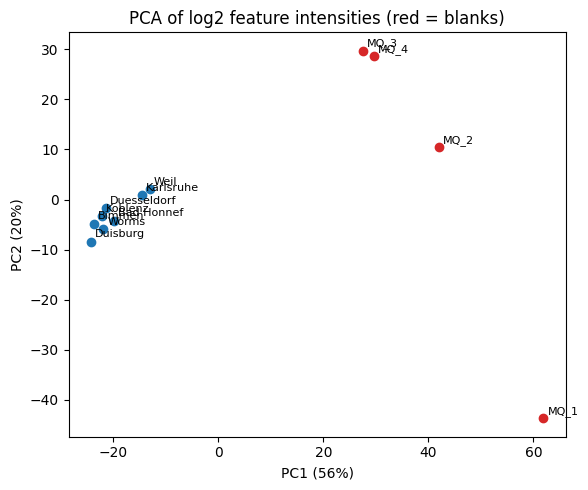

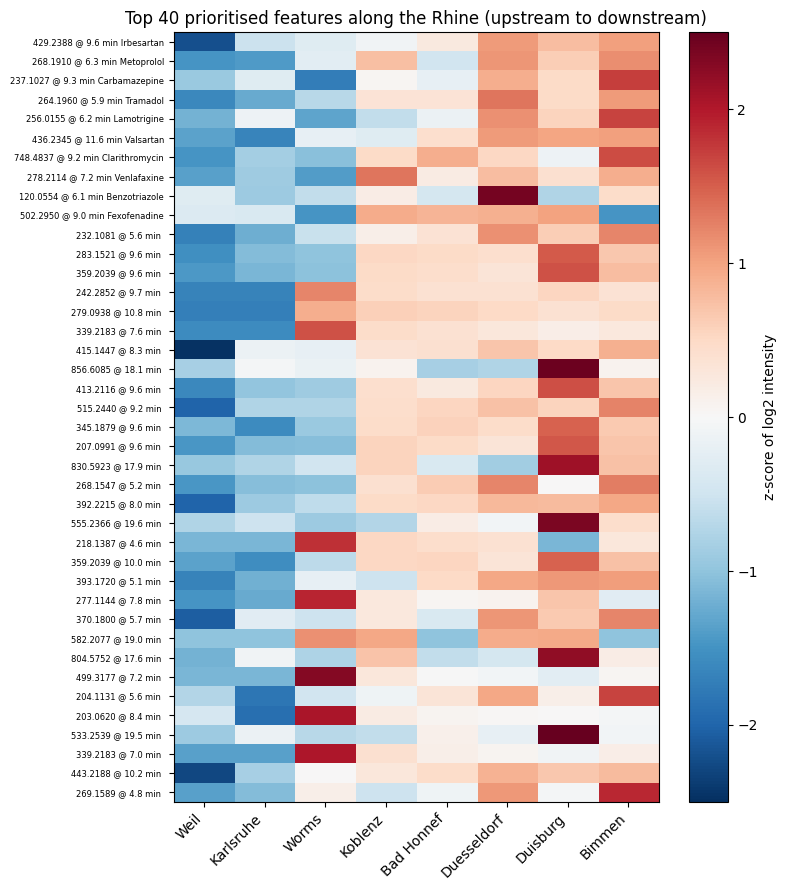

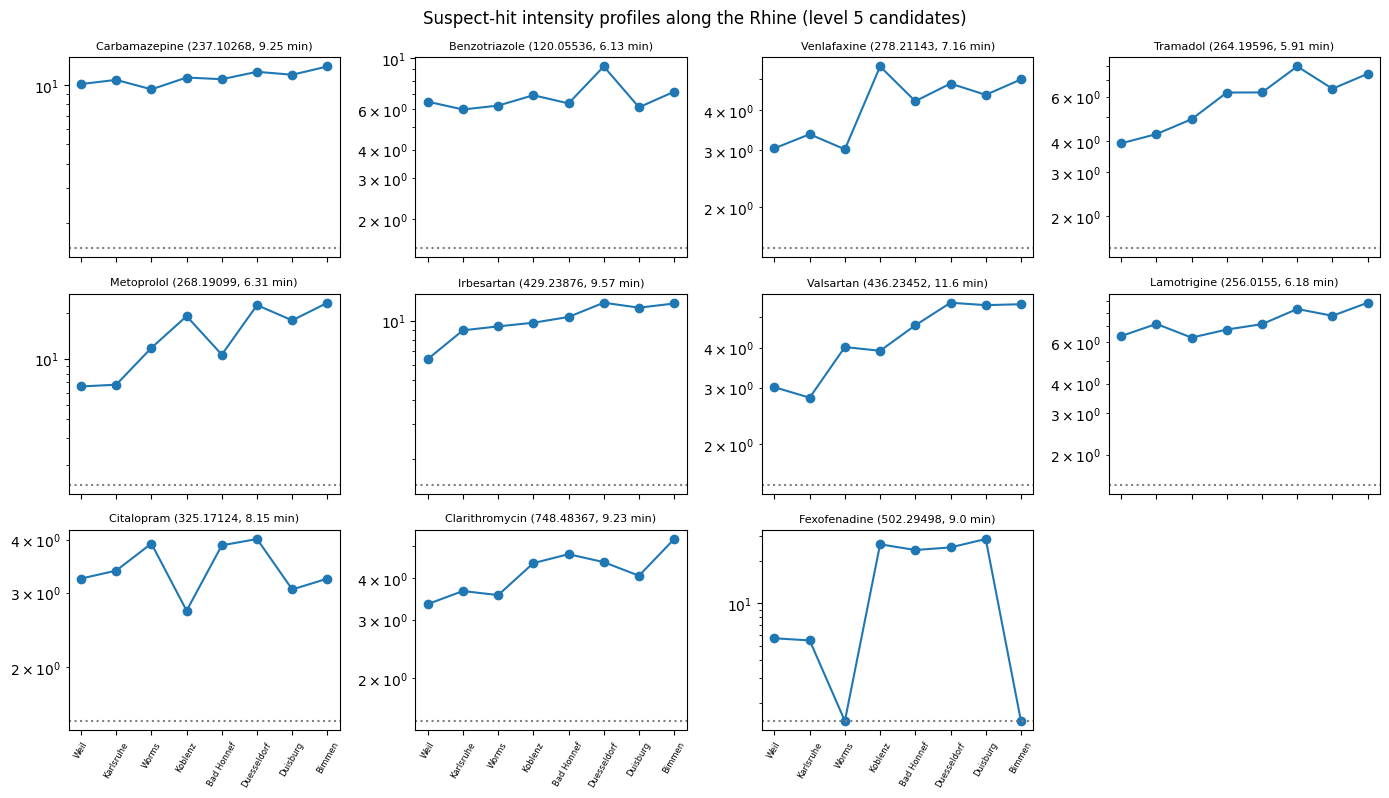

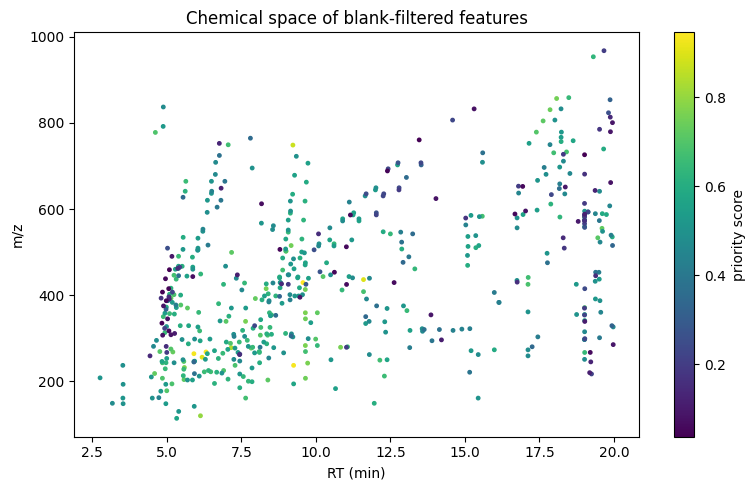

In [18]:
from sklearn.decomposition import PCA
cols = SAMPLES + BLANKS
Xp = np.log2(np.maximum(M.loc[(M[cols] > 0).sum(axis=1) >= 2, cols].values.T, LOD))
pc = PCA(n_components=2).fit(Xp); Z = pc.transform(Xp)
fig, ax = plt.subplots(figsize=(6, 5))
for i, c in enumerate(cols):
    ax.scatter(Z[i, 0], Z[i, 1], c="tab:red" if c in BLANKS else "tab:blue"); ax.annotate(c, Z[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pc.explained_variance_ratio_[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({pc.explained_variance_ratio_[1]*100:.0f}%)")
ax.set_title("PCA of log2 feature intensities (red = blanks)"); plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_pca.png", dpi=160); plt.show()

top = F.head(40)
Lt = np.log2(np.maximum(Sc.loc[top.index].values, LOD))
Zt = (Lt - Lt.mean(1, keepdims=True)) / np.where(Lt.std(1, keepdims=True) == 0, 1, Lt.std(1, keepdims=True))
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(Zt, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax.set_xticks(range(len(SAMPLES))); ax.set_xticklabels(SAMPLES, rotation=45, ha="right")
ax.set_yticks(range(len(top))); ax.set_yticklabels([f"{m:.4f} @ {r:.1f} min {s.split('|')[0]}" for m, r, s in zip(top.mz, top.rt_min, top.suspect)], fontsize=6)
plt.colorbar(im, label="z-score of log2 intensity"); ax.set_title("Top 40 prioritised features along the Rhine (upstream to downstream)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_top_features_heatmap.png", dpi=160); plt.show()

if len(hits):
    hu = hits.drop_duplicates("compound").head(12)
    ncols = 4
    nrows = int(np.ceil(len(hu) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.7 * nrows), sharex=True, squeeze=False)
    axes = axes.ravel()
    for ax, (_, h) in zip(axes, hu.iterrows()):
        vals = np.maximum(Sc.loc[h.cid, SAMPLES].values, LOD)
        ax.plot(range(len(SAMPLES)), vals, "o-"); ax.set_yscale("log"); ax.axhline(LOD, ls=":", c="gray")
        ax.set_title(f"{h.compound} ({h.mz_obs}, {h.rt_min} min)", fontsize=8)
        ax.set_xticks(range(len(SAMPLES))); ax.set_xticklabels(SAMPLES, rotation=60, fontsize=6)
    for ax in axes[len(hu):]:      # hide unused panels
        ax.axis("off")
    plt.suptitle("Suspect-hit intensity profiles along the Rhine (level 5 candidates)"); plt.tight_layout()
    plt.savefig(FIG_DIR / "fig4_suspect_profiles.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(F.rt_min, F.mz, c=F.score, s=6, cmap="viridis"); plt.colorbar(sc, label="priority score")
ax.set_xlabel("RT (min)"); ax.set_ylabel("m/z"); ax.set_title("Chemical space of blank-filtered features")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_mz_rt_space.png", dpi=160); plt.show()

19. Manual suspect lookup

In [19]:
def lookup(mz_t, ppm=10):
    sel = M.index[np.abs(info.mz - mz_t) / mz_t * 1e6 <= ppm]
    out = M.loc[sel].copy()
    out.insert(0, "rt_min", (info.loc[sel, "rt"] / 60).round(2))
    out.insert(0, "mz", info.loc[sel, "mz"].round(4))
    return out.round(2)
 
for name in ["Clarithromycin", "Sitagliptin", "Diclofenac", "Caffeine", "Benzotriazole", "Gabapentin", "Sulfamethoxazole"]:
    print("\n", name, round(mono(SUSPECTS[name]) + PROTON, 4))
    t = lookup(mono(SUSPECTS[name]) + PROTON)
    print(t.to_string() if len(t) else "   no feature group near this mass")


 Clarithromycin 748.4842
sample      mz  rt_min  Weil  Karlsruhe  Worms  Koblenz  Bad Honnef  Duesseldorf  Duisburg  Bimmen  MQ_1  MQ_2  MQ_3  MQ_4
cid                                                                                                                       
5193    748.48    9.23  2.68       2.94   3.34     4.49        5.15         4.83      4.67    5.57   0.0   0.0   0.0   0.0

 Sitagliptin 408.1254
sample      mz  rt_min  Weil  Karlsruhe  Worms  Koblenz  Bad Honnef  Duesseldorf  Duisburg  Bimmen  MQ_1  MQ_2  MQ_3  MQ_4
cid                                                                                                                       
623     408.13   16.07   0.0        0.0    0.0      0.0         0.0          0.0       0.0     0.0   0.0   0.0   0.0   0.0

 Diclofenac 296.024
   no feature group near this mass

 Caffeine 195.0877
   no feature group near this mass

 Benzotriazole 120.0556
sample      mz  rt_min  Weil  Karlsruhe  Worms  Koblenz  Bad Honnef  Duesseld

20. Top unknown features and event-like candidates

In [20]:
cols_show = ["mz", "rt_min", "n_sites", "rho", "jump_up", "jump_site", "persist", "n_ms2", "score"]
print("Top 20 UNKNOWN features by score:")
print(F[F.suspect == ""].head(20)[cols_show].round(3).to_string())
ev = F[(F.jump_up >= 4) & (F.persist >= 0.8) & (F.n_ms2 > 0)].sort_values("jump_up", ascending=False)
print(f"\nEvent-like features (>= 16x jump, persist >= 80%, with MS2): {len(ev)}")
print(ev.head(25)[cols_show].round(3).to_string())
print("\nEvent-like features per jump site:"); print(ev.jump_site.value_counts().reindex(SAMPLES).fillna(0).astype(int).to_string())
ev.to_csv(OUT / "event_like_features.csv")

Top 20 UNKNOWN features by score:
           mz  rt_min  n_sites    rho  jump_up    jump_site  persist  n_ms2  score
cid                                                                               
1701  232.108   5.588        8  0.976    0.721  Duesseldorf    1.000      3  0.766
619   283.152   9.647        8  0.881    1.712     Duisburg    1.000     11  0.764
660   359.204   9.647        8  0.881    1.712     Duisburg    1.000     12  0.763
32    242.285   9.723        6  0.323    9.536        Worms    1.000     36  0.762
45    279.094  10.828        6  0.180    7.667        Worms    1.000      7  0.761
163   339.218   7.640        6  0.180    7.520        Worms    1.000      9  0.761
2916  415.145   8.331        8  0.952    0.740        Worms    1.000      8  0.754
228   856.608  18.076        7  0.455    5.356     Duisburg    1.000      5  0.751
2233  413.212   9.645        8  0.952    1.333     Duisburg    1.000      7  0.750
2809  515.244   9.169        8  0.976    0.633  Duess

21. Extracted-ion chromatogram viewer

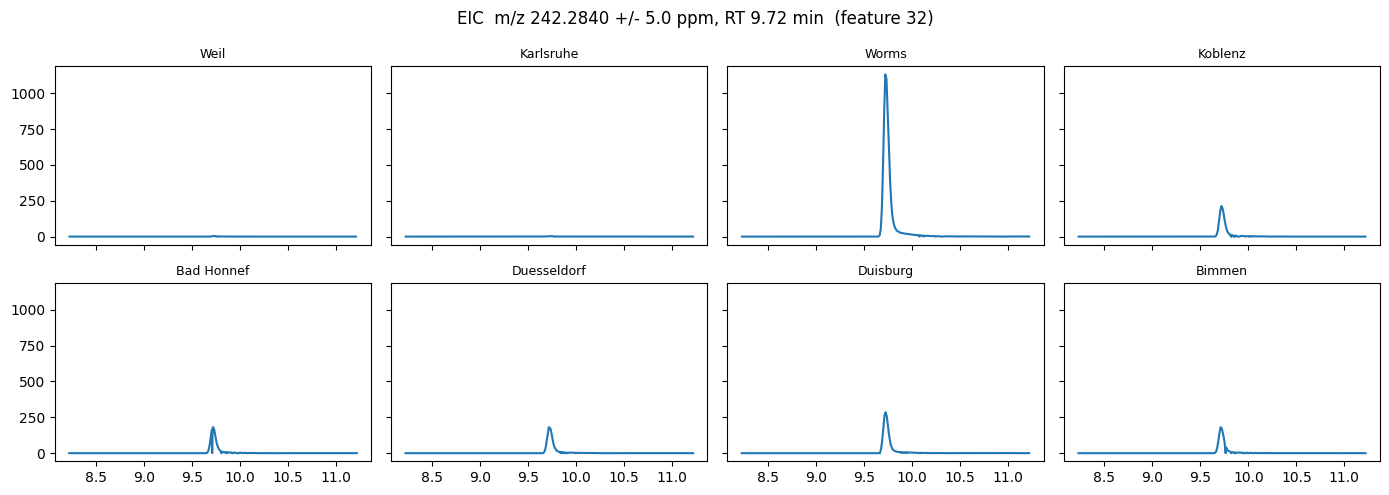

In [21]:
def plot_eic(cid, ppm=5.0, win=90.0):
    mz0, rt0 = F.loc[cid, "mz_raw"], F.loc[cid, "rt"]
    fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharex=True, sharey=True)
    for ax, s in zip(axes.ravel(), SAMPLES):
        path = meta.loc[meta.name == s, "path"].iloc[0]
        scan_rt, mz_s, it_s, sid_s = load_ms1_flat(path)
        tol = mz0 * ppm * 1e-6
        lo, hi = np.searchsorted(mz_s, [mz0 - tol, mz0 + tol])
        a, b = np.searchsorted(scan_rt, [rt0 - win, rt0 + win])
        sid, v = sid_s[lo:hi], it_s[lo:hi]
        m = (sid >= a) & (sid < b)
        eic = np.bincount(sid[m] - a, weights=v[m], minlength=b - a)
        ax.plot(scan_rt[a:b] / 60, eic); ax.set_title(s, fontsize=9)
    fig.suptitle(f"EIC  m/z {mz0:.4f} +/- {ppm} ppm, RT {rt0/60:.2f} min  (feature {cid})")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"eic_feature_{cid}.png", dpi=160); plt.show()
 
plot_eic(32)

22. Export

In [22]:
with open(OUT / "tier1_ms2.mgf", "w") as fh:
    for fid, r in F[(F.tier == "1") & (F.ms2_idx >= 0)].iterrows():
        rec = ms2_rows[int(r.ms2_idx)]; o = np.argsort(rec["mz"])
        pep = rec['pmz'] / (1 + (a + b * rec['pmz']) * 1e-6)
        fh.write(f"BEGIN IONS\nFEATURE_ID={fid}\nPEPMASS={pep:.5f}\nRTINSECONDS={rec['rt']:.1f}\nCHARGE=1+\nMSLEVEL=2\n")
        for m, i in zip(rec["mz"][o], rec["it"][o]): fh.write(f"{m:.5f} {i:.3f}\n")
        fh.write("END IONS\n\n")
params = dict(record=RECORD_ID, noise_quantile=NOISE_QUANTILE, noise_int=NOISE_INT, mass_error_ppm=MASS_ERR_PPM,
              group_ppm=PPM_TOL, group_rt_s=RT_TOL, blank_fold=BLANK_FOLD, min_sites=MIN_SITES, suspect_ppm=SUSPECT_PPM,
              weights=W, offset_ppm=OFFSET_PPM, apex_min=float(APEX_MIN), lod=float(LOD), suspect_ppm_used=SUSPECT_PPM, n_features_kept=int(len(F)), pyopenms=getattr(globals().get("oms", None), "__version__", "n/a"))
json.dump(params, open(OUT / "run_params.json", "w"), indent=2)
import shutil; shutil.make_archive(str(WORK / "rhine_pnta_results"), "zip", str(OUT))
print("Saved to", OUT, "(download the zip, and use Save Version > Save & Run All so outputs persist)")

Saved to /kaggle/working/wastewater_watch_results (download the zip, and use Save Version > Save & Run All so outputs persist)


23. Strict homologous-series detection

In [23]:
UNITS = {"C2H4O (ethoxylate)": 44.026215, "C3H6O (propoxylate)": 58.041865}
MIN_RUN = 4
RT_STEP = 20.0
MIN_CORR = 0.5
MZ_TOL = 0.002
 
ids = F.index.values; mzr = F.mz_raw.values; rts = F.rt.values
prof = np.log2(np.maximum(Sc.loc[ids].values, LOD))
sid_arr = np.full(len(ids), -1); unit_arr = np.array([""] * len(ids), dtype=object); len_arr = np.zeros(len(ids), dtype=int)
next_id = 0
for uname, u in UNITS.items():
    parent = list(range(len(ids)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for ia in range(len(ids)):
        d = mzr - mzr[ia] - u
        for ib in np.where((np.abs(d) <= MZ_TOL) & (np.abs(rts - rts[ia]) <= RT_STEP))[0]:
            c = np.corrcoef(prof[ia], prof[ib])[0, 1]
            if np.isfinite(c) and c >= MIN_CORR:
                ra, rb = find(ia), find(ib)
                if ra != rb: parent[ra] = rb
    comp = np.array([find(i) for i in range(len(ids))])
    for cmp in np.unique(comp):
        members = np.where(comp == cmp)[0]
        if len(members) < MIN_RUN: continue
        k = np.round((mzr[members] - mzr[members].min()) / u).astype(int)
        ks = np.unique(k); runs = []; start = prev = ks[0]
        for v in ks[1:]:
            if v != prev + 1: runs.append((start, prev)); start = v
            prev = v
        runs.append((start, prev))
        best = max(runs, key=lambda r: r[1] - r[0])
        run_len = best[1] - best[0] + 1
        if run_len >= MIN_RUN:
            sel = members[(k >= best[0]) & (k <= best[1])]
            sid_arr[sel] = next_id; unit_arr[sel] = uname; len_arr[sel] = run_len; next_id += 1
 
F["series_id"] = pd.Series(sid_arr, index=ids).reindex(F.index).values
F["series_unit"] = pd.Series(unit_arr, index=ids).reindex(F.index).values
F["series_len"] = pd.Series(len_arr, index=ids).reindex(F.index).values
ser = F[F.series_id >= 0].sort_values(["series_id", "mz_raw"])
print(f"{ser.series_id.nunique()} strict series (>= {MIN_RUN} consecutive units), {len(ser)} features")
for sid, g in ser.groupby("series_id"):
    print(f"\nSeries {sid}: {g.series_unit.iloc[0]}, {len(g)} members, sites detected {int(g.n_sites.min())}-{int(g.n_sites.max())}")
    print(g[["mz_raw", "rt_min", "n_sites", "jump_site", "jump_up"]].round(3).to_string())
 
last = len(SAMPLES) - 1
ev2 = F[(F.jump_up >= 4) & (F.persist >= 0.8) & (F.n_ms2 > 0) & (F.jump_site.map(SAMPLES.index) < last)].sort_values("jump_up", ascending=False)
ev2 = ev2.assign(in_series=ev2.series_id >= 0)
print(f"\nStricter event-like list: {len(ev2)} features, {int(ev2.in_series.sum())} belong to a strict series")
print(ev2.jump_site.value_counts().reindex(SAMPLES).fillna(0).astype(int).to_string())
ev2.to_csv(OUT / "event_like_features_strict.csv")

8 strict series (>= 4 consecutive units), 48 features

Series 0: C2H4O (ethoxylate), 5 members, sites detected 8-8
       mz_raw  rt_min  n_sites    jump_site  jump_up
cid                                                 
4204  358.242   4.935        8  Duesseldorf    0.394
3565  402.268   5.090        8  Duesseldorf    0.449
3137  446.295   5.239        8  Duesseldorf    0.632
4095  490.321   5.392        8  Duesseldorf    0.674
6121  534.347   5.548        8   Bad Honnef    0.477

Series 1: C2H4O (ethoxylate), 7 members, sites detected 2-2
       mz_raw  rt_min  n_sites jump_site  jump_up
cid                                              
1871  442.299   9.398        2    Bimmen    3.611
1228  486.325   9.467        2    Bimmen    4.364
991   530.352   9.530        2    Bimmen    4.737
954   574.378   9.587        2    Bimmen    4.791
1076  618.405   9.636        2    Bimmen    4.517
1380  662.431   9.680        2    Bimmen    4.132
2186  706.457   9.733        2    Bimmen    3.445

Se

24. Worms features: plume or independent signals?

In [24]:
# Are the Worms 'event' features a uniform plume, or independent signals?
w = ev2[ev2.jump_site == "Worms"].index
down = [s for s in SAMPLES[3:]]
ratio = Sc.loc[w, "Worms"] / Sc.loc[w, down].replace(0, np.nan).median(axis=1)
out = F.loc[w, ["mz_raw", "rt_min", "n_sites", "n_ms2"]].assign(worms_over_downstream=ratio.round(1)).sort_values("worms_over_downstream")
print(out.to_string())
print("\nIf the ratios are all similar, one plume or one sample effect is the likely explanation; widely different ratios suggest independent sources.")

          mz_raw     rt_min  n_sites  n_ms2  worms_over_downstream
cid                                                               
45    279.092445  10.827825        6      7                    2.3
1066  194.116752   5.170625        6      3                    4.3
1581  317.120322   6.100375        5      5                    5.2
1896  243.082705   4.850767        6      5                    5.3
1794  229.153707   4.946383        5     11                    5.5
983   277.113089   7.828725        7      7                    6.3
690   218.137499   4.588833        5     17                    6.5
967   298.073112   9.992275        6     15                    6.7
912   339.216884   6.985583        6      1                    6.7
32    242.283952   9.723192        6     36                    6.8
1003  288.215826   7.133900        5      7                    6.9
1502  161.105983   7.643442        6      6                    7.2
657   203.060838   8.388917        7     11                   

25. MS2 ethoxylate-ladder check

In [25]:
EO = 44.026215
TOL = 0.005
 
def eo_pairs(rec):
    mz = np.sort(rec["mz"].astype(float))
    if len(mz) < 3: return 0
    d = mz[None, :] - mz[:, None]
    return int((np.abs(d - EO) <= TOL).sum())
 
def ladder_stats(cid):
    r = F.loc[cid]; idxs = ms2_near(r.mz_raw, r.rt)
    pairs = [eo_pairs(ms2_rows[j]) for j in idxs]
    return len(idxs), int(sum(p >= 2 for p in pairs)), (max(pairs) if pairs else 0)
 
rows = []
for sid, g in F[F.series_id >= 0].groupby("series_id"):
    for cid, r in g.sort_values("mz_raw").iterrows():
        n_ms2, n_lad, mx = ladder_stats(cid)
        rows.append(dict(series=sid, cid=cid, mz=round(r.mz_raw, 3), rt_min=round(r.rt_min, 2), n_ms2=n_ms2, ms2_with_ladder=n_lad, max_pairs=mx))
res = pd.DataFrame(rows)
print(res.to_string())
tot = res.groupby("series")[["n_ms2", "ms2_with_ladder"]].sum()
tot["fraction"] = (tot.ms2_with_ladder / tot.n_ms2.replace(0, np.nan)).round(2)
print("\nPer series:"); print(tot.to_string())

ctrl_ids = F[(F.series_id < 0) & (F.n_ms2 > 0)].sample(min(150, int(((F.series_id < 0) & (F.n_ms2 > 0)).sum())), random_state=0).index
c = np.array([ladder_stats(i)[:2] for i in ctrl_ids])
print(f"\nControl (non-series features): {c[:, 1].sum()} of {c[:, 0].sum()} MS2 spectra show a ladder = {c[:, 1].sum() / max(c[:, 0].sum(), 1):.3f}")
print("A credible ethoxylate series should show a much higher fraction than the control.")
res.to_csv(OUT / "series_ms2_ladder_check.csv", index=False)

    series   cid       mz  rt_min  n_ms2  ms2_with_ladder  max_pairs
0        0  4204  358.242    4.94     20               20          7
1        0  3565  402.268    5.09     18               18          7
2        0  3137  446.295    5.24     29               29          8
3        0  4095  490.321    5.39     16               16          7
4        0  6121  534.347    5.55      6                5          5
5        1  1871  442.299    9.40      1                1          3
6        1  1228  486.325    9.47      3                3         15
7        1   991  530.352    9.53      2                2         10
8        1   954  574.378    9.59      4                4         13
9        1  1076  618.405    9.64      2                2         11
10       1  1380  662.431    9.68      3                3         17
11       1  2186  706.457    9.73      1                1         16
12       2  3382  356.190    5.25      2                0          1
13       2  2565  400.216    5.46 

27. RDKit: structures, formula validation and physicochemical properties

Attaches a chemical structure (SMILES) to each suspect hit. RDKit recomputes the molecular formula and the [M+H]+ mass from the structure and checks that they agree with the formula used for the exact-mass search, which guards against typos. It also calculates logP, polar surface area (TPSA), hydrogen-bond donors and rotatable bonds, and draws the structures.

*Note: SMILES are flat (no stereochemistry) and should be verified against PubChem.*

In [26]:
!pip install -q rdkit

                   formula  formula_matches_notebook  dmz_mDa  logP   TPSA  HBD  rot_bonds
compound                                                                                  
Carbamazepine    C15H12N2O                      True     -0.0  3.39   46.3    1          0
Benzotriazole       C6H5N3                      True     -0.0  0.96   41.6    1          0
Venlafaxine      C17H27NO2                      True     -0.0  3.04   32.7    1          5
Tramadol         C16H25NO2                      True     -0.0  2.63   32.7    1          4
Metoprolol       C15H25NO3                      True     -0.0  1.61   50.7    2          9
Irbesartan       C25H28N6O                      True     -0.0  4.78   87.1    1          7
Valsartan       C24H29N5O3                      True     -0.0  4.16  112.1    2         10
Lamotrigine      C9H7Cl2N5                      True     -0.0  2.01   90.7    2          1
Citalopram      C20H21FN2O                      True     -0.0  3.81   36.3    0          5

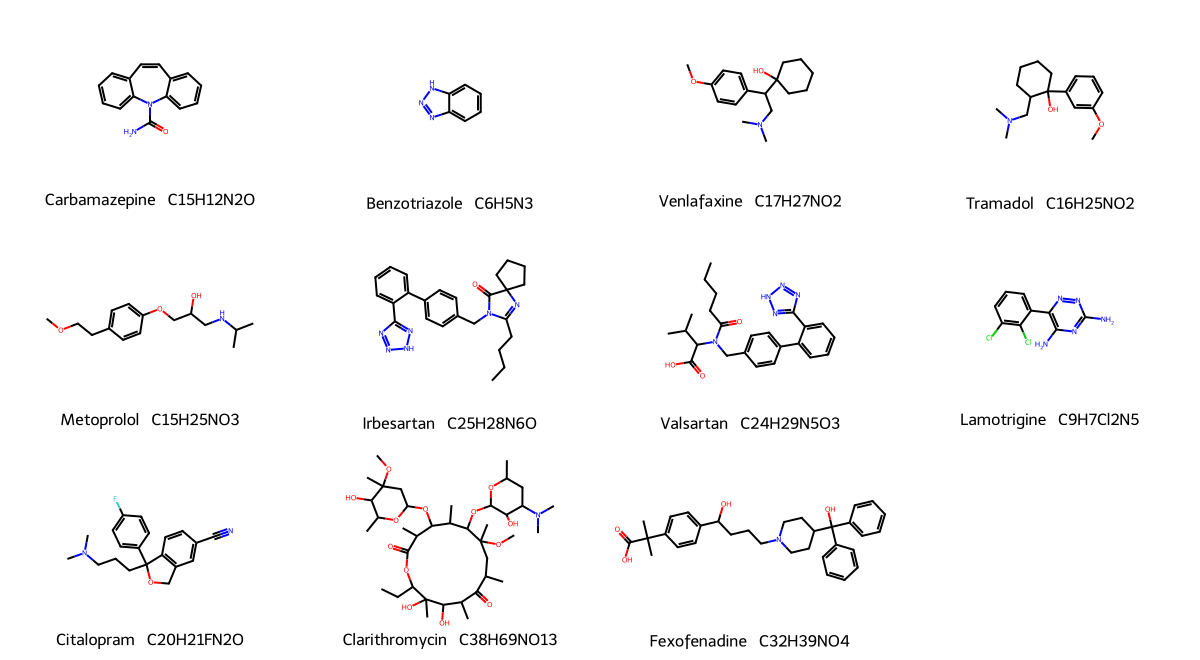

In [27]:
from collections import Counter
from IPython.display import display
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors, Draw
RDLogger.DisableLog("rdApp.*")
 
# Flat (no stereochemistry) SMILES for the compounds that produced a suspect hit.
# VERIFY against PubChem before reporting; the formula check below catches typos but not wrong isomers.
SMILES = {
    "Carbamazepine":  "NC(=O)N1c2ccccc2C=Cc2ccccc12",
    "Benzotriazole":  "c1ccc2[nH]nnc2c1",
    "Venlafaxine":    "COc1ccc(cc1)C(CN(C)C)C1(O)CCCCC1",
    "Tramadol":       "COc1cccc(c1)C1(O)CCCCC1CN(C)C",
    "Metoprolol":     "COCCc1ccc(OCC(O)CNC(C)C)cc1",
    "Irbesartan":     "CCCCC1=NC2(CCCC2)C(=O)N1Cc1ccc(cc1)-c1ccccc1-c1nn[nH]n1",
    "Valsartan":      "CCCCC(=O)N(Cc1ccc(cc1)-c1ccccc1-c1nn[nH]n1)C(C(C)C)C(O)=O",
    "Lamotrigine":    "Nc1nnc(c(N)n1)-c1cccc(Cl)c1Cl",
    "Citalopram":     "CN(C)CCCC1(OCc2cc(C#N)ccc12)c1ccc(F)cc1",
    "Clarithromycin": "CCC1C(C(C(C(=O)C(CC(C(C(C(C(C(=O)O1)C)OC2CC(C(C(O2)C)O)(C)OC)C)OC3C(C(CC(O3)C)N(C)C)O)(C)OC)C)C)O)(C)O",
    "Fexofenadine":   "CC(C)(C(=O)O)c1ccc(cc1)C(O)CCCN1CCC(CC1)C(O)(c1ccccc1)c1ccccc1",
}
 
rows = []
for name, smi in SMILES.items():
    m = Chem.MolFromSmiles(smi)
    if m is None:
        print("Invalid SMILES:", name); continue
    f_rd = rdMolDescriptors.CalcMolFormula(m)
    mz_rd = Descriptors.ExactMolWt(m) + PROTON
    mz_nb = mono(SUSPECTS[name]) + PROTON
    rows.append(dict(compound=name, formula=f_rd, formula_matches_notebook=(f_rd == SUSPECTS[name]),
                     dmz_mDa=round((mz_rd - mz_nb) * 1000, 3),
                     logP=round(Crippen.MolLogP(m), 2), TPSA=round(rdMolDescriptors.CalcTPSA(m), 1),
                     HBD=rdMolDescriptors.CalcNumHBD(m), rot_bonds=rdMolDescriptors.CalcNumRotatableBonds(m)))
props = pd.DataFrame(rows).set_index("compound")
print(props.to_string())
assert props.formula_matches_notebook.all(), "A SMILES does not match its formula: fix it before continuing"
 
mols = [Chem.MolFromSmiles(SMILES[n]) for n in props.index]
img = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 220),
                           legends=[f"{n}  {props.loc[n, 'formula']}" for n in props.index])
if hasattr(img, "save"): img.save(FIG_DIR / "fig6_suspect_structures.png")
display(img)
props.to_csv(OUT / "suspect_structure_properties.csv")

28. RDKit: retention-time plausibility (RT vs calculated logP)

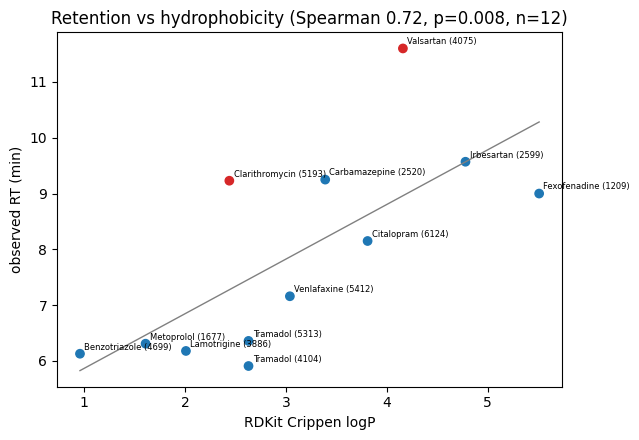

          compound   cid  rt_min  logP  rt_resid
7        Valsartan  4075   11.60  4.16      2.64
10  Clarithromycin  5193    9.23  2.44      1.95


In [28]:
from scipy.stats import spearmanr
 
h = hits.merge(props[["logP", "TPSA"]], left_on="compound", right_index=True)
rho_s, p_s = spearmanr(h.logP, h.rt_min)
slope, icpt = np.polyfit(h.logP, h.rt_min, 1)
h["rt_resid"] = h.rt_min - (icpt + slope * h.logP)
z = (h.rt_resid - h.rt_resid.mean()) / h.rt_resid.std()
h["rt_outlier"] = z.abs() > 1.5
 
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(h.logP, h.rt_min, c=np.where(h.rt_outlier, "tab:red", "tab:blue"))
xs = np.linspace(h.logP.min(), h.logP.max(), 20); ax.plot(xs, icpt + slope * xs, lw=1, c="gray")
for _, r in h.iterrows():
    ax.annotate(f"{r.compound} ({r.cid})", (r.logP, r.rt_min), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("RDKit Crippen logP"); ax.set_ylabel("observed RT (min)")
ax.set_title(f"Retention vs hydrophobicity (Spearman {rho_s:.2f}, p={p_s:.3f}, n={len(h)})")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig7_rt_vs_logp.png", dpi=160); plt.show()
print(h.loc[h.rt_outlier, ["compound", "cid", "rt_min", "logP", "rt_resid"]].round(2).to_string()
      if h.rt_outlier.any() else "No RT outliers (|z| > 1.5)")

**Result (28):** Calculated logP and observed retention time are related only loosely. Valsartan (+2.6 min) and clarithromycin (+2.0 min) elute later than predicted. This most likely reflects the limits of Crippen logP for ionisable acids and large macrolides rather than misidentification. Spearman rho = ___ (n = 11). The check is a plausibility screen; it cannot confirm an identity.

29. RDKit: in-silico fragmentation and decoy test

Not testable (no acyclic bond to cut): ['Benzotriazole']

Carbamazepine: explained peaks in the best spectrum (m/z, fragment, ppm)
[(194.0973, 'C14H10N +2H', 4.3), (193.0891, 'C14H10N +1H', 2.6), (192.0814, 'C14H10N +0H', 3.5), (191.0729, 'C14H10N -1H', -0.4)]

Metoprolol: explained peaks in the best spectrum (m/z, fragment, ppm)
[(116.1067, 'C6H14NO +0H', -2.1), (135.0812, 'C9H11O +0H', 6.0), (58.0653, 'C3H8N +0H', 2.9)]

Clarithromycin: explained peaks in the best spectrum (m/z, fragment, ppm)
[(158.1179, 'C8H16NO2 +0H', 1.9)]

          compound  feature  n_spectra  median_explained  best_explained
0   Carbamazepine     2520         10              0.55            0.75
1     Venlafaxine     5412         10              0.31            0.40
2        Tramadol     4104         14              0.58            0.73
3      Metoprolol     1677         17              0.02            0.05
4      Irbesartan     2599         10              0.00            0.08
5       Valsartan     4075     

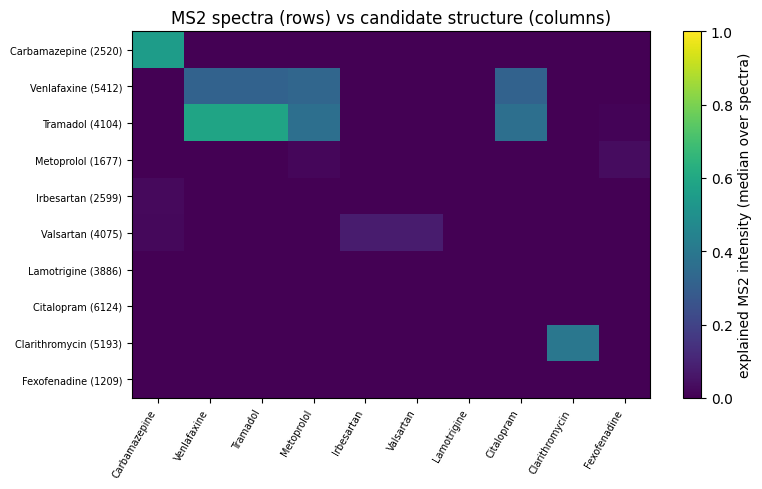

In [29]:
MASS_A, MASS_B = a, b                     # freeze the mass-error model so later cells cannot overwrite it
PT = Chem.GetPeriodicTable()
HMASS = 1.00782503207
DSHIFT = (-1, 0, 1, 2)
 
def hill(cnt):
    s = ""
    for el in ("C", "H"):
        if cnt.get(el): s += el + (str(cnt[el]) if cnt[el] > 1 else "")
    for el in sorted(k for k in cnt if k not in ("C", "H")):
        s += el + (str(cnt[el]) if cnt[el] > 1 else "")
    return s
 
FRAG_CACHE = {}
def fragment_candidates(name):
    """{formula of piece: monoisotopic mass of piece} from all single acyclic heavy-atom bond cuts."""
    if name in FRAG_CACHE: return FRAG_CACHE[name]
    mol = Chem.AddHs(Chem.MolFromSmiles(SMILES[name]))
    pieces = {}
    for bond in mol.GetBonds():
        x, y = bond.GetBeginAtom(), bond.GetEndAtom()
        if bond.IsInRing() or bond.GetBondType() != Chem.BondType.SINGLE: continue
        if x.GetAtomicNum() == 1 or y.GetAtomicNum() == 1: continue
        rw = Chem.RWMol(mol); rw.RemoveBond(x.GetIdx(), y.GetIdx())
        for idxs in Chem.GetMolFrags(rw):
            atoms = [mol.GetAtomWithIdx(i) for i in idxs]
            pieces[hill(Counter(at.GetSymbol() for at in atoms))] = sum(
                PT.GetMostCommonIsotopeMass(at.GetAtomicNum()) for at in atoms)
    FRAG_CACHE[name] = pieces
    return pieces
 
def explain(name, rec, tol_ppm=7.0, min_rel=0.05):      # 7 ppm: MS2 fragment masses scatter more than MS1
    """Fraction of MS2 intensity (peaks >= 5% of base peak, below the precursor) explained by the structure."""
    pieces = fragment_candidates(name)
    if not pieces: return np.nan, 0, 0, []       # e.g. benzotriazole: only ring bonds, nothing to cut
    labels, m0 = list(pieces), np.array(list(pieces.values()))
    cand = (m0[None, :] + np.array(DSHIFT)[:, None] * HMASS - ELECTRON).ravel()
    lab = [f"{l} {d:+d}H" for d in DSHIFT for l in labels]
    mz = rec["mz"].astype(float); it = rec["it"].astype(float)
    mzc = mz / (1 + (MASS_A + MASS_B * mz) * 1e-6)
    sel = (it >= min_rel * it.max()) & (mzc < rec["pmz"] - 1.0)
    mzc, it = mzc[sel], it[sel]
    if len(mzc) == 0: return np.nan, 0, 0, []
    err = (mzc[:, None] - cand[None, :]) / cand[None, :] * 1e6
    best = np.abs(err).argmin(axis=1); e_best = err[np.arange(len(mzc)), best]
    ok = np.abs(e_best) <= tol_ppm
    detail = [(round(float(m_), 4), lab[j], round(float(e_), 1)) for m_, j, e_, o in zip(mzc, best, e_best, ok) if o]
    return float(it[ok].sum() / it.sum()), int(ok.sum()), len(mzc), detail
 
# (a) Score against ALL MS2 spectra linked to the feature (not just one): a single chimeric or weak spectrum can mislead.
def linked_spectra(cid):
    return [ms2_rows[j] for j in ms2_near(F.at[cid, "mz_raw"], F.at[cid, "rt"])]
 
def explain_median(name, recs):
    vals = [explain(name, r)[0] for r in recs]
    vals = [v for v in vals if np.isfinite(v)]
    return float(np.median(vals)) if vals else np.nan
 
TESTABLE = [n for n in SMILES if fragment_candidates(n)]      # structures with at least one acyclic bond
print("Not testable (no acyclic bond to cut):", [n for n in SMILES if n not in TESTABLE])
spectra = []                                                   # (compound, cid, [ms2 records])
for _, hh in hits.iterrows():
    recs = linked_spectra(hh.cid)
    if recs and hh.compound in TESTABLE: spectra.append((hh.compound, hh.cid, recs))
 
summary = []
for name, cid, recs in spectra:
    res = [explain(name, r) for r in recs]
    fr = [r_[0] for r_ in res if np.isfinite(r_[0])]
    summary.append(dict(compound=name, feature=cid, n_spectra=len(recs),
                        median_explained=round(float(np.median(fr)), 2) if fr else np.nan,
                        best_explained=round(max(fr), 2) if fr else np.nan))
    if name in ("Carbamazepine", "Metoprolol", "Clarithromycin") and fr:
        j = int(np.argmax([r_[0] if np.isfinite(r_[0]) else -1 for r_ in res]))
        print(f"\n{name}: explained peaks in the best spectrum (m/z, fragment, ppm)"); print(res[j][3][:8])
print("\n", pd.DataFrame(summary).to_string())
 
# (b) decoy test: score every feature's spectra against EVERY structure (median over its spectra).
names = TESTABLE
rowlab = [f"{n} ({c})" for n, c, _ in spectra]
S = pd.DataFrame(index=rowlab, columns=names, dtype=float)
for (n, c, recs), rl in zip(spectra, rowlab):
    for cand_name in names:
        S.loc[rl, cand_name] = explain_median(cand_name, recs)
 
# Tie-aware verdict. (A plain rank hides ties: a row of all zeros would give every candidate "rank 1".)
MARGIN = 0.05                                   # scores closer than this are treated as a tie
verdicts = []
for (n, c, _), rl in zip(spectra, rowlab):
    true = S.loc[rl, n]; decoys = S.loc[rl].drop(n)
    if not np.isfinite(true) or true < 0.05:
        v = "uninformative (<5% of MS2 intensity explained)"
    elif (decoys > true + MARGIN).any():
        v = "decoy wins: " + ", ".join(decoys[decoys > true + MARGIN].index)
    else:
        tied = decoys[decoys >= true - MARGIN].index.tolist()
        v = "discriminating" if not tied else "tied with " + ", ".join(tied)
    verdicts.append(dict(spectrum=rl, true_score=round(float(true), 2) if np.isfinite(true) else np.nan,
                         best_decoy=round(float(decoys.max()), 2), verdict=v))
print("\nDecoy test (true structure vs", len(names) - 1, "decoys):")
print(pd.DataFrame(verdicts).to_string(index=False))
 
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(S.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(S))); ax.set_yticklabels(S.index, fontsize=7)
plt.colorbar(im, label="explained MS2 intensity (median over spectra)")
ax.set_title("MS2 spectra (rows) vs candidate structure (columns)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig8_ms2_decoy_matrix.png", dpi=160); plt.show()
S.to_csv(OUT / "ms2_structure_decoy_matrix.csv")
pd.DataFrame(verdicts).to_csv(OUT / "ms2_structure_decoy_verdicts.csv", index=False)

**Result (29):** In-silico fragmentation explains 55% of the MS2 intensity for carbamazepine and 40% for clarithromycin (desosamine fragment, m/z 158.118, +1.9 ppm), and no decoy structure competes, which supports their tentative level-3 assignments. Metoprolol's side-chain fragment (m/z 116.107) is found, but most of its intensity comes from rearrangement and water-loss fragments that single-bond cleavage cannot generate. Tramadol, venlafaxine, citalopram and metoprolol tie because a shared low-mass amine fragment (C3H8N+, m/z 58.065) matches all four. For the sartans, lamotrigine, citalopram and fexofenadine, fewer than 10% of the intensity is explained, which is expected for ring-based fragmentation.

**Interpretation.** The test supports carbamazepine and clarithromycin, does not contradict any other assignment, and cannot discriminate structurally similar amines. A proper evaluation needs ring-opening fragmentation (MetFrag, CFM-ID) or reference spectra.

30. Results

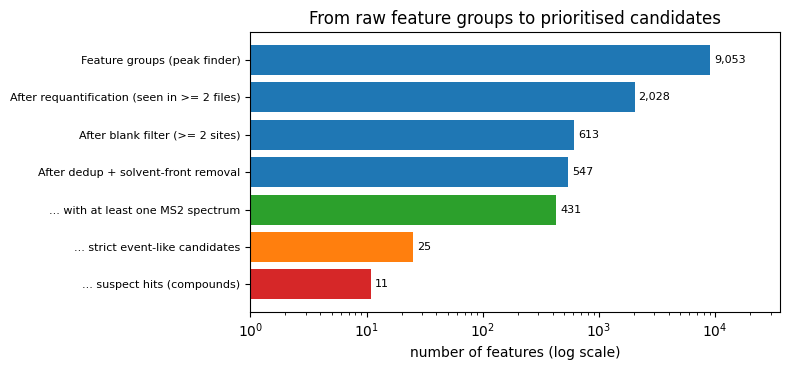

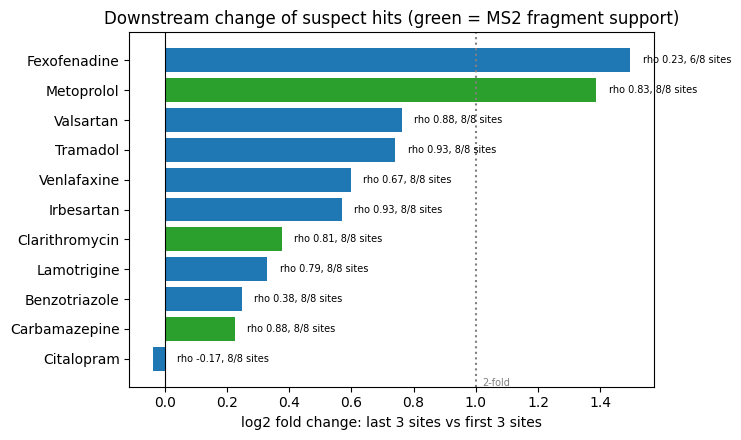

In [30]:
steps = [
    ("Feature groups (peak finder)",          len(M_ffm)),
    ("After requantification (seen in >= 2 files)", len(M)),
    ("After blank filter (>= 2 sites)",       int(keep.sum())),
    ("After dedup + solvent-front removal",   len(F)),
    ("... with at least one MS2 spectrum",    int((F.n_ms2 > 0).sum())),
    ("... strict event-like candidates",      len(ev2)),
    ("... suspect hits (compounds)",          int(hits.compound.nunique())),
]
fig, ax = plt.subplots(figsize=(8, 3.8))
labels, counts = zip(*steps)
cols_ = ["tab:blue"] * 4 + ["tab:green", "tab:orange", "tab:red"]
ax.barh(range(len(steps)), counts, color=cols_); ax.set_xscale("log"); ax.invert_yaxis()
ax.set_yticks(range(len(steps))); ax.set_yticklabels(labels, fontsize=8)
for i, c in enumerate(counts): ax.text(c * 1.08, i, f"{c:,}", va="center", fontsize=8)
ax.set_xlim(1, max(counts) * 4); ax.set_xlabel("number of features (log scale)")
ax.set_title("From raw feature groups to prioritised candidates")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig9_pipeline_funnel.png", dpi=160); plt.show()
 

best = hits.sort_values(["n_sites", "rho"], ascending=False).drop_duplicates("compound").set_index("compound")
eff = pd.DataFrame({"fold": F.loc[best.cid.values, "down_minus_up"].values,      # log2(last 3 sites) - log2(first 3 sites)
                    "rho": best.rho.values, "n_sites": best.n_sites.values}, index=best.index).sort_values("fold")
tentative = set(frag_df.loc[frag_df.verdict.str.startswith("tentative"), "compound"])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(eff.index, eff.fold, color=["tab:green" if c in tentative else "tab:blue" for c in eff.index])
ax.axvline(0, c="k", lw=0.8); ax.axvline(1, ls=":", c="gray"); ax.text(1.02, -0.9, "2-fold", fontsize=7, color="gray")
for i, (c, r) in enumerate(eff.iterrows()):
    ax.text(max(r.fold, 0) + 0.04, i, f"rho {r.rho:.2f}, {int(r.n_sites)}/8 sites", va="center", fontsize=7)
ax.set_xlabel("log2 fold change: last 3 sites vs first 3 sites")
ax.set_title("Downstream change of suspect hits (green = MS2 fragment support)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig10_suspect_effect_sizes.png", dpi=160); plt.show()

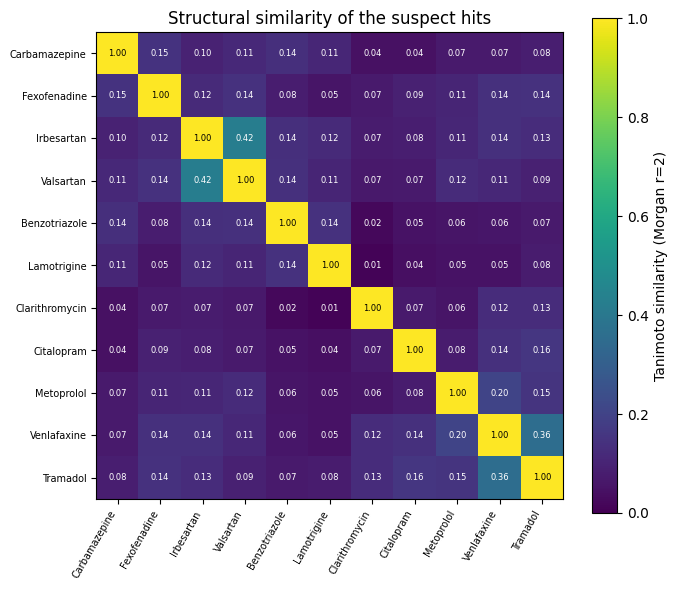

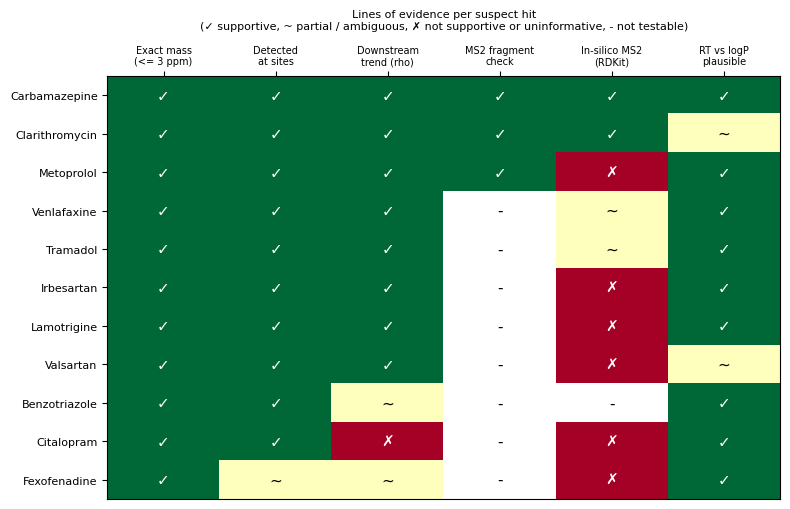

                Exact mass\n(<= 3 ppm)  Detected\nat sites  Downstream\ntrend (rho)  MS2 fragment\ncheck  In-silico MS2\n(RDKit)  RT vs logP\nplausible
Carbamazepine                      1.0                 1.0                      1.0                  1.0                     1.0                    1.0
Clarithromycin                     1.0                 1.0                      1.0                  1.0                     1.0                    0.5
Metoprolol                         1.0                 1.0                      1.0                  1.0                     0.0                    1.0
Venlafaxine                        1.0                 1.0                      1.0                  NaN                     0.5                    1.0
Tramadol                           1.0                 1.0                      1.0                  NaN                     0.5                    1.0
Irbesartan                         1.0                 1.0                      1.0     

In [31]:
from rdkit import DataStructs
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
try:                                                    # RDKit >= 2022.09
    from rdkit.Chem import rdFingerprintGenerator
    _gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    _fp = lambda m: _gen.GetFingerprint(m)
except Exception:                                       # older RDKit
    from rdkit.Chem import AllChem
    _fp = lambda m: AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=2048)
 
# --- Figure 11: Tanimoto similarity (Morgan radius 2). Explains WHY some MS2 results are tied. ---
order = list(SMILES)
fps = [_fp(Chem.MolFromSmiles(SMILES[n])) for n in order]
T = np.array([DataStructs.BulkTanimotoSimilarity(f, fps) for f in fps])
idx = leaves_list(linkage(squareform(1 - T, checks=False), "average"))
Tn = T[np.ix_(idx, idx)]; nm = [order[i] for i in idx]
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(Tn, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(nm))); ax.set_xticklabels(nm, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(nm))); ax.set_yticklabels(nm, fontsize=7)
for i in range(len(nm)):
    for j in range(len(nm)):
        ax.text(j, i, f"{Tn[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if Tn[i, j] < 0.6 else "k")
plt.colorbar(im, label="Tanimoto similarity (Morgan r=2)"); ax.set_title("Structural similarity of the suspect hits")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig11_suspect_similarity.png", dpi=160); plt.show()
 
# --- Figure 12: one row per suspect, one column per line of evidence ---
# Thresholds below are heuristic and for COMMUNICATION only; they are not a statistical confidence score.
vd = pd.DataFrame(verdicts).set_index("spectrum")
rt_flag = h.groupby("compound").rt_outlier.any()
tested_frag = set(frag_df.compound)
E = {}
for comp, r in best.iterrows():
    key = [k for k in vd.index if k.startswith(comp + " (")]
    if not key: sil = np.nan                                           # no testable structure / no MS2
    else:
        v = vd.loc[key[0]]
        sil = 1.0 if (v.verdict == "discriminating" and v.true_score >= 0.3) else (0.5 if v.true_score >= 0.3 else 0.0)
    E[comp] = {
        "Exact mass\n(<= 3 ppm)": 1.0,
        "Detected\nat sites": 1.0 if r.n_sites == 8 else (0.5 if r.n_sites >= 6 else 0.0),
        "Downstream\ntrend (rho)": 1.0 if r.rho >= 0.5 else (0.5 if r.rho >= 0.2 else 0.0),
        "MS2 fragment\ncheck": (1.0 if comp in tentative else 0.0) if comp in tested_frag else np.nan,
        "In-silico MS2\n(RDKit)": sil,
        "RT vs logP\nplausible": 0.5 if bool(rt_flag.get(comp, False)) else 1.0,
    }
E = pd.DataFrame(E).T
E = E.loc[E.fillna(0).sum(axis=1).sort_values(ascending=False).index]
E.to_csv(OUT / "suspect_evidence_matrix.csv")
 
cmap = plt.get_cmap("RdYlGn").copy(); cmap.set_bad("white")
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.imshow(np.ma.masked_invalid(E.values.astype(float)), cmap=cmap, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(E.shape[1])); ax.set_xticklabels(E.columns, fontsize=7)
ax.set_yticks(range(E.shape[0])); ax.set_yticklabels(E.index, fontsize=8)
ax.xaxis.tick_top()
sym = {1.0: "\u2713", 0.5: "~", 0.0: "\u2717"}
for i in range(E.shape[0]):
    for j in range(E.shape[1]):
        v = E.values[i, j]
        ax.text(j, i, "-" if np.isnan(v) else sym[v], ha="center", va="center", fontsize=11,
                color="black" if (np.isnan(v) or v == 0.5) else "white")
ax.set_title("Lines of evidence per suspect hit\n(\u2713 supportive, ~ partial / ambiguous, \u2717 not supportive or uninformative, - not testable)",
             fontsize=8, pad=34)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig12_evidence_matrix.png", dpi=160, bbox_inches="tight"); plt.show()
print(E.round(1).to_string())

In [32]:
FRAG, SIL = "MS2 fragment\ncheck", "In-silico MS2\n(RDKit)"
rows = []
for comp, r in E.iterrows():
    n_feat = int((hits.compound == comp).sum())
    if r[FRAG] == 1.0:
        level = 3
        s = r[SIL]
        sup = "not testable" if pd.isna(s) else ("supported, no decoy competes" if s == 1.0
                                                 else ("ambiguous (tied with decoys)" if s == 0.5 else "weak / not explained"))
        basis = f"diagnostic fragments found in measured MS2; in-silico MS2: {sup}"
    else:
        level = 5
        basis = "exact mass only"
        if r[SIL] == 0.5: basis += "; MS2 matches a shared, non-diagnostic fragment (tied with other structures)"
    if n_feat > 1: basis += f"; {n_feat} candidate features (isomers or duplicates), assignment ambiguous"
    rows.append(dict(compound=comp, schymanski_level=level, basis=basis))
conf = pd.DataFrame(rows).set_index("compound")
conf.to_csv(OUT / "suspect_confidence_levels.csv")
print(conf.to_string())
print("\nLevel counts:", conf.schymanski_level.value_counts().sort_index().to_dict())

                schymanski_level                                                                                                                                                            basis
compound                                                                                                                                                                                         
Carbamazepine                  3                                                                          diagnostic fragments found in measured MS2; in-silico MS2: supported, no decoy competes
Clarithromycin                 3                                                                          diagnostic fragments found in measured MS2; in-silico MS2: supported, no decoy competes
Metoprolol                     3                                                                                  diagnostic fragments found in measured MS2; in-silico MS2: weak / not explained
Venlafaxine                   

## Interpretation notes and limitations
- The spatial gradient is a **proxy** for time; it supports method development, not a true early-warning test.
- Suspect hits are level 5 (exact mass) unless the MS2 fragment check supports them (then a tentative level 3). Verify fragment values in MassBank first; reference standards or library matches are needed for level 2 or 1.
- Hotspot / tributary explanations (for example Worms, Mosel, Ruhr) are hypotheses, not findings.
- Normalisation assumes most features do not change between sites; if run order equals river order, drift and real gradients cannot be fully separated without QC injections.
- Report the sensitivity of results to NOISE_QUANTILE, the blank choice and the score weights.
- Next: MetFrag + PubChemLite on tier1_ms2.mgf, matchms against MassBank, the paired negative-mode file.